In [1]:
import copy

import config as cfg
from data_acquirer import get_data, gen_data
from data_processor import process
from solver import solve_pdpcr,mass_solve
import visualization
from operator import itemgetter
import matplotlib.pyplot as plt

import pandas as pd

In [2]:
"""
SOLVE_METHOD ={
1: solve_vrp_sumofcosts,
2: solve_flow_makespan,
3: solve_vrp_makespan,
4: solve_vrp_ver2
}
"""

method = 2
random_data = False
total_robots = 5
total_tasks = 10
data_name = 'data4'

In [3]:
if method == 4 or method ==5:
    is_depot_task = True
else:
    is_depot_task = False
if random_data:
    raw = gen_data(total_robots, total_tasks, False, is_depot_task)
else:
    raw = get_data(data_name,'csv', is_depot_task)

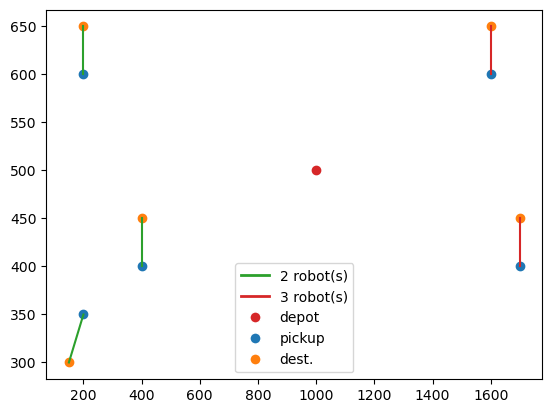

In [4]:
visualization.plot_map(raw)

In [ ]:
processed_data = process(raw, method) 
solve_result = solve_pdpcr(processed_data, total_robots, method)

In [ ]:
sol = solve_result['sol']
x = solve_result['x']
f = solve_result['f']

In [ ]:
sol.get_value_df(f)

In [ ]:
f

In [ ]:
MOVED_EDGE_GETTER ={
    1:visualization.get_moved_edges,
    2:visualization.get_moved_edges_flow
}

In [ ]:
node_idx_mapper = {node.index: node for node in processed_data.nodes}
moved_edges = MOVED_EDGE_GETTER[method](solve_result)
paths = visualization.get_paths(moved_edges,total_robots)
tasks_path = visualization.get_tasks_path(paths, processed_data.nodes)
paths_coor = visualization.get_paths_coor(paths,node_idx_mapper)
edge_paths = visualization.get_edge_paths(paths)
if method ==2:
    node_idx_mapper = {node.index: node for node in processed_data.nodes[:-1]}

## Visualization

In [ ]:
import networkx as nx

In [ ]:
G = nx.DiGraph()
V =[node for node in node_idx_mapper.keys()]
E = moved_edges
pos = {idx: node.coor for idx,node in node_idx_mapper.items()}
        
G.add_nodes_from(V)        
G.add_edges_from(E)

color_map = []
for node in V:
    if node ==0:
        color_map.append('red')
    elif node_idx_mapper[node].node_type ==1:
        color_map.append('C0')
    elif node_idx_mapper[node].node_type ==2:
        color_map.append('C1')

In [ ]:
edges_color = []
edges_style = []
for edge in E:
    for i in range(len(edge_paths)):
        if edge in edge_paths[i]:
            edges_color.append(f'C{i}')
            edges_style.append((1,(3+i*2,5)))

In [ ]:
nx.draw(G,pos = pos, node_color = color_map,node_size =50, edge_color = edges_color, style = edges_style, arrowsize =15)
if random_data == False:
    plt.savefig(f"img/{data_name}result.png", format="PNG")
else:
    plt.savefig(f"img/{seed_num}_{current_time}result_random.png", format="PNG")
plt.show()

## Mass Solve

In [ ]:
Rs = [1,2,3,4]
Ts = [5,10,15]
total_instances = 3
full_solved_instances = []
for T in Ts:
    for R in Rs:
        print(f'__________________________solving for {T} tasks and {R} robot__________________________')
        solved_instances = mass_solve(T,R,2,total_instances = total_instances)
        [full_solved_instances.append(solved_instance) for solved_instance in solved_instances]

In [ ]:
def results_to_df(full_solved_instances, compact = True):
    solved_dict = [solve_instance.__dict__ for solve_instance in full_solved_instances]
    df_solved = pd.DataFrame(solved_dict)
    if compact == True:
        df_solved.drop(['data','seed','instance_num'],axis =1, inplace = True,)
    return df_solved

In [ ]:
df_results = results_to_df(full_solved_instances)
df_results = df_results.round(1)

In [ ]:
df_results

In [ ]:
total_tasks = [len(solved_instance.data.tasks) for solved_instance in full_solved_instances]
total_robots = [(solved_instance.total_robots) for solved_instance in full_solved_instances]
# total_nodes = [len(solved_instance.data.nodes) for solved_instance in full_solved_instances]
orig_tasks = []
for T in Ts:
    for R in Rs:
        for _ in range(total_instances):
            orig_tasks.append(T)

In [ ]:
df_results['total_tasks'] = total_tasks
# df_results['total_nodes'] = total_nodes
df_results['orig_tasks'] = orig_tasks

In [ ]:
df_results = df_results[['total_robots','orig_tasks','solve_time','gap']]

In [ ]:
print(df_results.groupby(['total_robots','orig_tasks']).mean().reset_index().round(2).to_latex())

In [ ]:
df_results.groupby(['total_robots','orig_tasks']).mean().reset_index().round(2)

## Process data vrp ver 2